<a href="https://colab.research.google.com/github/San-Maansson/Stock_Analysis/blob/main/Heatmap_SPY.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import yfinance as yf

In [ ]:
# Download historical data for the GLD ETF with auto-adjustment for splits and dividends
ticker = "SPY"
data = yf.download(ticker, start="2006-01-01", end="2025-07-13", auto_adjust=True)

[*********************100%***********************]  1 of 1 completed


In [ ]:
# Calculate daily returns
data['Returns'] = data['Close'].pct_change()

In [ ]:
data['Returns']

,Returns
Date,
2006-01-03,NaN
2006-01-04,0.004735
2006-01-05,0.000629
2006-01-06,0.008321
2006-01-09,0.002569
...,...
2025-07-07,-0.007452
2025-07-08,-0.000548
2025-07-09,0.005997


In [ ]:
# Drop the first row with NaN returns
data = data.dropna()

# Extract year and month, converting month numbers to month names
data.loc[:, 'Year'] = data.index.year
data.loc[:, 'Month'] = data.index.strftime('%b')

In [ ]:
data

Price,Close,High,Low,Open,Volume,Returns,Year,Month
Ticker,SPY,SPY,SPY,SPY,SPY,,,
Date,,,,,,,,
1995-01-04,26.864584,26.864584,26.718581,26.855459,351800,0.004778,1995,Jan
1995-01-05,26.864584,26.928460,26.837208,26.882834,89800,0.000000,1995,Jan
1995-01-06,26.891956,27.010584,26.809830,26.919332,448400,0.001019,1995,Jan
1995-01-09,26.919336,26.919336,26.864585,26.882836,36800,0.001018,1995,Jan
1995-01-10,26.946716,27.092720,26.946716,26.983217,229800,0.001017,1995,Jan
...,...,...,...,...,...,...,...,...
2025-07-07,620.679993,624.030029,617.869995,623.359985,74814500,-0.007452,2025,Jul
2025-07-08,620.340027,622.109985,619.520020,621.349976,59024600,-0.000548,2025,Jul


In [ ]:
# Calculate average monthly returns
monthly_returns2 = data.groupby(['Year', 'Month'])['Returns'].mean().unstack()

# Ensure the months are in correct order
monthly_returns2 = monthly_returns2[['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']]

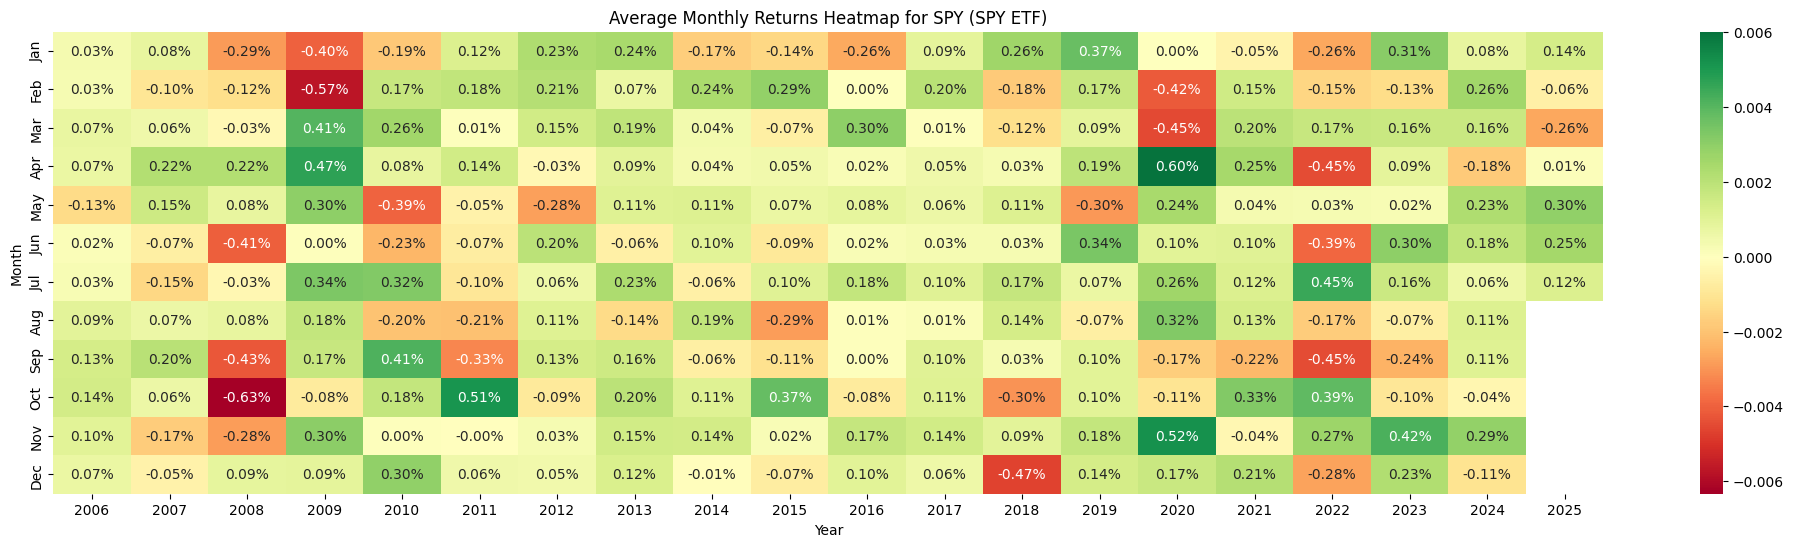

In [ ]:
# Plotting the heatmap with red, green, and yellow color scale, centred around 0
plt.figure(figsize=(25, 6)) # Increased width from 12 to 15
sns.heatmap(monthly_returns2.T, annot=True, fmt=".2%", cmap="RdYlGn", cbar=True, center=0)
plt.title(f"Average Monthly Returns Heatmap for {ticker} (SPY ETF)")
plt.show()

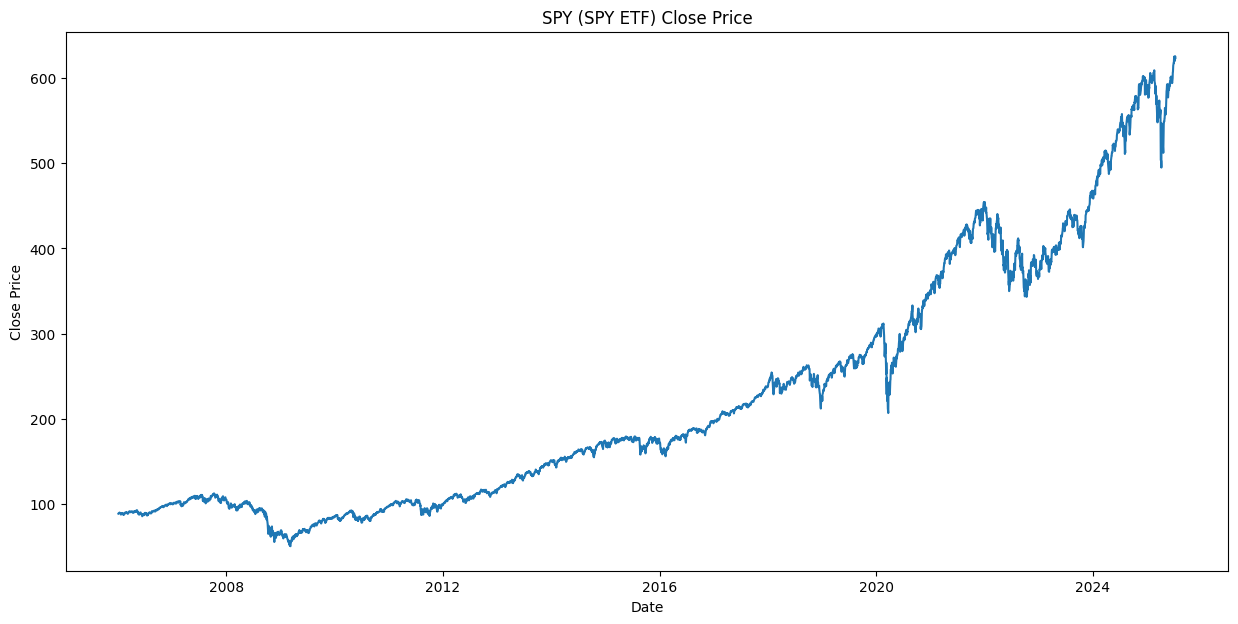

In [ ]:
plt.figure(figsize=(15, 7))
sns.lineplot(data=data, x=data.index, y=data['Close'].values.flatten())
plt.title(f'{ticker} (SPY ETF) Close Price')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.show()

In [ ]:
# Calculate rolling percentage change (e.g., over a 5-day window)
rolling_window = 5
data['Rolling_Pct_Change'] = data['Close'].pct_change(periods=rolling_window)

# Identify significant drops (e.g., 5% or more)
significant_drops = data[data['Rolling_Pct_Change'] <= -0.05]

/usr/local/lib/python3.11/dist-packages/matplotlib/text.py:1477: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  y = float(self.convert_yunits(y))


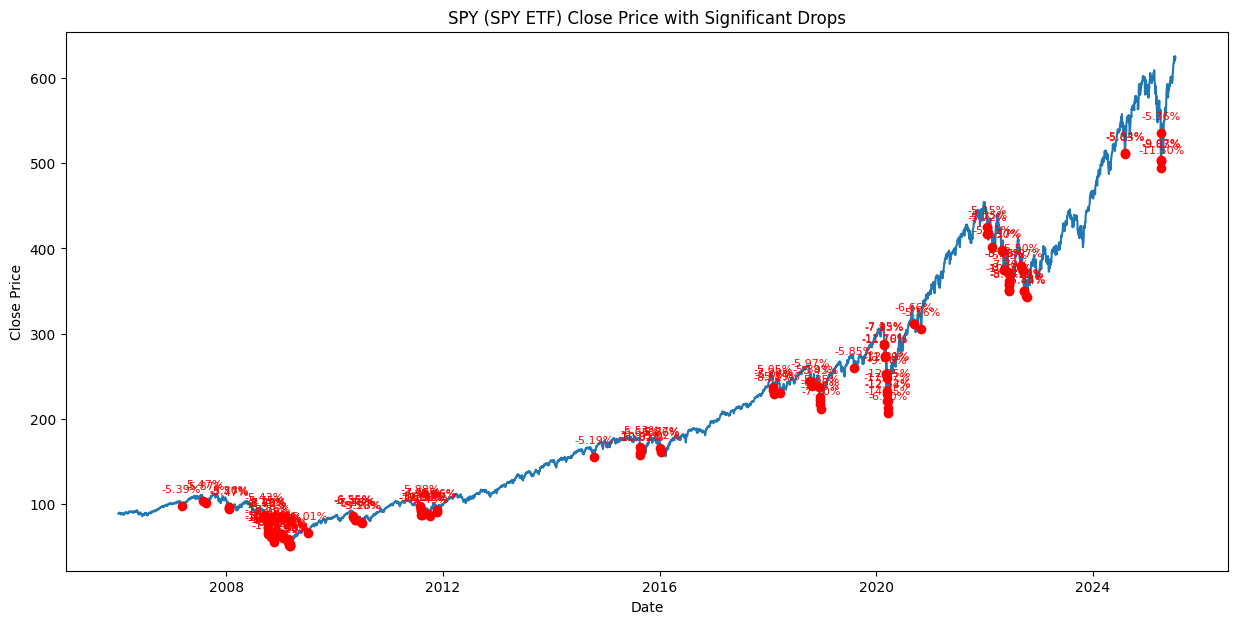

In [ ]:
plt.figure(figsize=(15, 7))
sns.lineplot(data=data, x=data.index, y=data['Close'].values.flatten())
plt.title(f'{ticker} (SPY ETF) Close Price with Significant Drops')
plt.xlabel('Date')
plt.ylabel('Close Price')

# Add annotations for significant drops
for date, row in significant_drops.iterrows():
    plt.annotate(f'{row["Rolling_Pct_Change"].item():.2%}', # Use .item() to get the scalar value
                 (date, row['Close']),
                 textcoords="offset points",
                 xytext=(0,10),
                 ha='center',
                 fontsize=8,
                 color='red')
    plt.plot(date, row['Close'], 'ro') # Mark the point with a red circle

plt.show()

In [ ]:
significant_drops

Price,Close,High,Low,Open,Volume,Returns,Year,Month,Rolling_Pct_Change
Ticker,SPY,SPY,SPY,SPY,SPY,,,,
Date,,,,,,,,,
2007-03-05,97.122375,98.699241,97.108230,97.532493,143750400,-0.009519,2007,Mar,-0.053868
2007-07-27,103.460602,106.141405,103.417825,105.670846,422987600,-0.019659,2007,Jul,-0.054658
2007-08-15,100.558739,102.997141,100.259288,101.756551,323834000,-0.013776,2007,Aug,-0.058667
2008-01-17,96.091583,99.296325,95.731501,99.245909,397892600,-0.025916,2008,Jan,-0.055631
2008-01-18,95.104980,97.236674,94.413628,97.035028,348561500,-0.010267,2008,Jan,-0.057724
...,...,...,...,...,...,...,...,...,...
2024-08-07,512.279419,525.050407,511.676938,521.968734,70698300,-0.006684,2024,Aug,-0.058369
2025-04-03,535.118042,546.354781,535.118042,543.503226,125986000,-0.049281,2025,Apr,-0.053573
